<a href="https://colab.research.google.com/github/deka-199/M5_DS_Decka-Bagas-Syaputra/blob/main/M5_DS_Dhecka_Bagas_Syaputra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [5]:
import os

os.listdir('/content')

['.config', 'paket_a_transaksi_pos_2024_2025.csv', 'sample_data']

In [6]:
# Membaca dataset CSV
df = pd.read_csv('/content/paket_a_transaksi_pos_2024_2025.csv')

# Menampilkan 5 baris pertama
display(df.head())

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


In [7]:
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

if file_name.endswith('.csv'):
    df = pd.read_csv(file_name)
elif file_name.endswith(('.xlsx', '.xls')):
    df = pd.read_excel(file_name)
else:
    raise ValueError("Format file tidak didukung")

display(df.head())

Saving paket_a_transaksi_pos_2024_2025.csv to paket_a_transaksi_pos_2024_2025 (1).csv


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


In [8]:
# Informasi struktur dataset
df.info()

# Statistik deskriptif
display(df.describe(include='all'))

# Jumlah baris dan kolom
print("Ukuran dataset:", df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_transaksi   5030 non-null   object
 1   tanggal        5030 non-null   object
 2   kode_gerai     5030 non-null   object
 3   kode_kasir     4769 non-null   object
 4   kode_produk    5030 non-null   object
 5   jumlah         5030 non-null   int64 
 6   harga_satuan   5030 non-null   object
 7   diskon_persen  5030 non-null   int64 
 8   status         5030 non-null   object
dtypes: int64(2), object(7)
memory usage: 353.8+ KB


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
count,5030,5030,5030,4769,5030,"5,030.00",5030,"5,030.00",5030
unique,5000,902,12,40,216,NaN,147,NaN,3
top,TRX0244203,2025-06-01,G01,K021,SGR1204,NaN,11000,NaN,SELESAI
freq,2,18,478,142,96,NaN,197,NaN,4749
mean,NaN,NaN,NaN,NaN,NaN,5.59,NaN,2.56,NaN
std,NaN,NaN,NaN,NaN,NaN,68.79,NaN,5.21,NaN
min,NaN,NaN,NaN,NaN,NaN,-12.00,NaN,0.00,NaN
25%,NaN,NaN,NaN,NaN,NaN,1.00,NaN,0.00,NaN
50%,NaN,NaN,NaN,NaN,NaN,2.00,NaN,0.00,NaN
75%,NaN,NaN,NaN,NaN,NaN,3.00,NaN,0.00,NaN


Ukuran dataset: (5030, 9)


In [9]:
# Menghilangkan spasi pada nama kolom
df.columns = df.columns.str.strip().str.lower()

# Memeriksa nama kolom
print(df.columns.tolist())

['id_transaksi', 'tanggal', 'kode_gerai', 'kode_kasir', 'kode_produk', 'jumlah', 'harga_satuan', 'diskon_persen', 'status']


In [10]:
kolom_tanggal = 'tanggal_transaksi'
kolom_status = 'status'
kolom_harga = 'harga'
kolom_jumlah = 'jumlah'
kolom_diskon = 'diskon'

In [11]:
kolom_tanggal = 'order_date'

In [12]:
# Menghitung missing value
missing = df.isnull().sum()

# Menghitung persentase missing value
persentase_missing = (missing / len(df)) * 100

# Membuat tabel missing value
tabel_missing = pd.DataFrame({
    'Jumlah Missing Value': missing,
    'Persentase (%)': persentase_missing
})

display(tabel_missing[tabel_missing['Jumlah Missing Value'] > 0])

,Jumlah Missing Value,Persentase (%)
kode_kasir,261,5.19


In [14]:
print(df.columns.tolist())

['id_transaksi', 'tanggal', 'kode_gerai', 'kode_kasir', 'kode_produk', 'jumlah', 'harga_satuan', 'diskon_persen', 'status']


In [20]:
kolom_tanggal = 'tanggal'
kolom_status = 'status'
kolom_harga = 'harga_satuan'
kolom_jumlah = 'jumlah'
kolom_diskon = 'diskon_persen'

In [21]:
for kolom in df.columns:
    print(kolom)

id_transaksi
tanggal
kode_gerai
kode_kasir
kode_produk
jumlah
harga_satuan
diskon_persen
status


In [22]:
kolom_wajib = [
    kolom_tanggal,
    kolom_status,
    kolom_harga,
    kolom_jumlah
]

df = df.dropna(subset=kolom_wajib)

df[kolom_diskon] = df[kolom_diskon].fillna(0)

print("Missing value setelah penanganan:")
print(df.isnull().sum())

Missing value setelah penanganan:
id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64


In [23]:
kolom_tanggal = 'tanggal'
kolom_harga = 'harga_satuan'
kolom_jumlah = 'jumlah'
kolom_diskon = 'diskon_persen'

# Memeriksa nama kolom yang tersedia
print(df.columns.tolist())

['id_transaksi', 'tanggal', 'kode_gerai', 'kode_kasir', 'kode_produk', 'jumlah', 'harga_satuan', 'diskon_persen', 'status']


In [24]:
# Mencari kemungkinan nama kolom status
kandidat_status = [
    'status',
    'status_transaksi',
    'transaction_status'
]

kolom_status = next(
    (k for k in kandidat_status if k in df.columns),
    None
)

if kolom_status is not None:
    print("Kolom status ditemukan:", kolom_status)
    print(df[kolom_status].value_counts(dropna=False))
else:
    print("Dataset tidak memiliki kolom status transaksi.")

Kolom status ditemukan: status
status
SELESAI    4749
BATAL       191
RETUR        90
Name: count, dtype: int64


In [25]:
# Kolom yang wajib tersedia untuk perhitungan
kolom_wajib = [
    kolom_tanggal,
    kolom_harga,
    kolom_jumlah,
    kolom_diskon
]

# Menghapus data yang kosong pada kolom penting
df = df.dropna(subset=kolom_wajib).copy()

# Memastikan diskon yang kosong dianggap 0%
df[kolom_diskon] = df[kolom_diskon].fillna(0)

print("Missing value setelah penanganan:")
print(df.isnull().sum())

Missing value setelah penanganan:
id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64


In [26]:
# Mengubah tanggal menjadi datetime
df[kolom_tanggal] = pd.to_datetime(
    df[kolom_tanggal],
    errors='coerce'
)

# Mengubah kolom numerik
kolom_numerik = [
    kolom_harga,
    kolom_jumlah,
    kolom_diskon
]

for kolom in kolom_numerik:
    df[kolom] = pd.to_numeric(
        df[kolom],
        errors='coerce'
    )

# Menghapus data yang gagal dikonversi
df = df.dropna(
    subset=[
        kolom_tanggal,
        kolom_harga,
        kolom_jumlah,
        kolom_diskon
    ]
).copy()

# Memeriksa tipe data
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4793 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id_transaksi   4793 non-null   object        
 1   tanggal        4793 non-null   datetime64[ns]
 2   kode_gerai     4793 non-null   object        
 3   kode_kasir     4543 non-null   object        
 4   kode_produk    4793 non-null   object        
 5   jumlah         4793 non-null   int64         
 6   harga_satuan   4793 non-null   float64       
 7   diskon_persen  4793 non-null   int64         
 8   status         4793 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(5)
memory usage: 374.5+ KB


In [27]:
if kolom_status is not None:

    # Menyamakan format teks status
    df[kolom_status] = (
        df[kolom_status]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # Melihat kategori status
    print("Kategori status transaksi:")
    print(df[kolom_status].value_counts())

    # Menentukan status yang valid
    status_valid = [
        'sukses',
        'success',
        'completed',
        'berhasil',
        'selesai'
    ]

    # Mengambil transaksi yang berhasil
    df_valid = df[
        df[kolom_status].isin(status_valid)
    ].copy()

else:
    # Jika tidak ada kolom status
    df_valid = df.copy()

print("Jumlah transaksi awal:", len(df))
print("Jumlah transaksi yang dianalisis:", len(df_valid))

Kategori status transaksi:
status
selesai    4526
batal       183
retur        84
Name: count, dtype: int64
Jumlah transaksi awal: 4793
Jumlah transaksi yang dianalisis: 4526


In [28]:
print("Diskon terkecil:", df_valid[kolom_diskon].min())
print("Diskon terbesar:", df_valid[kolom_diskon].max())

print("\nDistribusi diskon:")
print(df_valid[kolom_diskon].value_counts().sort_index().head(20))

Diskon terkecil: 0
Diskon terbesar: 20

Distribusi diskon:
diskon_persen
0     3471
5      310
10     373
15     243
20     129
Name: count, dtype: int64


In [29]:
# Menghitung total harga sebelum diskon
df_valid['total_harga'] = (
    df_valid[kolom_harga] *
    df_valid[kolom_jumlah]
)

# Menghitung nilai diskon dalam rupiah
df_valid['nilai_diskon'] = (
    df_valid['total_harga'] *
    df_valid[kolom_diskon] / 100
)

# Menghitung pendapatan bersih
df_valid['pendapatan_bersih'] = (
    df_valid['total_harga'] -
    df_valid['nilai_diskon']
)

# Menampilkan hasil perhitungan
display(
    df_valid[
        [
            kolom_harga,
            kolom_jumlah,
            kolom_diskon,
            'total_harga',
            'nilai_diskon',
            'pendapatan_bersih'
        ]
    ].head(10)
)

,harga_satuan,jumlah,diskon_persen,total_harga,nilai_diskon,pendapatan_bersih
0,"13,000.00",4,0,"52,000.00",0.00,"52,000.00"
1,"21,000.00",1,0,"21,000.00",0.00,"21,000.00"
3,"6,500.00",2,0,"13,000.00",0.00,"13,000.00"
5,"45,500.00",12,10,"546,000.00","54,600.00","491,400.00"
6,"18,000.00",1,0,"18,000.00",0.00,"18,000.00"
7,"47,500.00",4,10,"190,000.00","19,000.00","171,000.00"
10,"33,500.00",4,10,"134,000.00","13,400.00","120,600.00"
11,"30,500.00",2,0,"61,000.00",0.00,"61,000.00"
12,"11,500.00",1,20,"11,500.00","2,300.00","9,200.00"
13,"4,500.00",6,0,"27,000.00",0.00,"27,000.00"


In [30]:
# Mengambil tahun dari tanggal transaksi
df_valid['tahun'] = df_valid[kolom_tanggal].dt.year

# Melihat jumlah transaksi berdasarkan tahun
jumlah_transaksi = (
    df_valid['tahun']
    .value_counts()
    .sort_index()
)

display(jumlah_transaksi)

,count
tahun,
2024,2257
2025,2269


In [31]:
# Memilih transaksi tahun 2024 dan 2025
df_tahunan = df_valid[
    df_valid['tahun'].isin([2024, 2025])
].copy()

# Menghitung total pendapatan bersih setiap tahun
pendapatan_tahunan = (
    df_tahunan
    .groupby('tahun')['pendapatan_bersih']
    .sum()
    .reindex([2024, 2025], fill_value=0)
)

# Membuat tabel hasil
hasil_pendapatan = pd.DataFrame({
    'Tahun': [2024, 2025],
    'Total Pendapatan Bersih': [
        pendapatan_tahunan.loc[2024],
        pendapatan_tahunan.loc[2025]
    ]
})

display(hasil_pendapatan)

,Tahun,Total Pendapatan Bersih
0,2024,"381,265,717.90"
1,2025,"239,740,530.90"


In [32]:
pendapatan_2024 = pendapatan_tahunan.loc[2024]
pendapatan_2025 = pendapatan_tahunan.loc[2025]

selisih = pendapatan_2025 - pendapatan_2024

if pendapatan_2024 != 0:
    persentase_perubahan = (
        selisih / pendapatan_2024
    ) * 100
else:
    persentase_perubahan = np.nan

print(f"Pendapatan 2024 : Rp{pendapatan_2024:,.2f}")
print(f"Pendapatan 2025 : Rp{pendapatan_2025:,.2f}")
print(f"Selisih         : Rp{selisih:,.2f}")

if pd.notna(persentase_perubahan):
    print(f"Perubahan       : {persentase_perubahan:.2f}%")

    if selisih > 0:
        print("Kesimpulan: Pendapatan mengalami peningkatan.")
    elif selisih < 0:
        print("Kesimpulan: Pendapatan mengalami penurunan.")
    else:
        print("Kesimpulan: Pendapatan tidak mengalami perubahan.")
else:
    print("Persentase perubahan tidak dapat dihitung karena pendapatan 2024 bernilai nol.")

Pendapatan 2024 : Rp381,265,717.90
Pendapatan 2025 : Rp239,740,530.90
Selisih         : Rp-141,525,187.00
Perubahan       : -37.12%
Kesimpulan: Pendapatan mengalami penurunan.


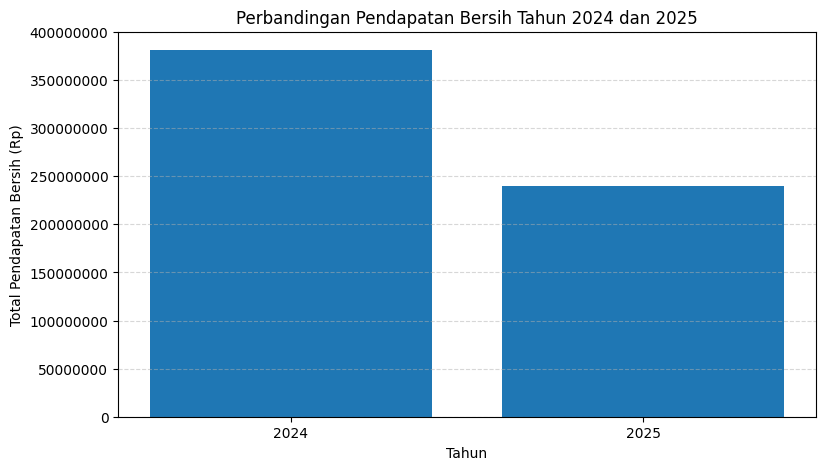

In [33]:
plt.figure(figsize=(9, 5))

plt.bar(
    hasil_pendapatan['Tahun'].astype(str),
    hasil_pendapatan['Total Pendapatan Bersih']
)

plt.title('Perbandingan Pendapatan Bersih Tahun 2024 dan 2025')
plt.xlabel('Tahun')
plt.ylabel('Total Pendapatan Bersih (Rp)')

plt.ticklabel_format(
    style='plain',
    axis='y'
)

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [36]:
ringkasan = pd.DataFrame({
    'Keterangan': [
        'Jumlah Transaksi Dianalisis',
        'Pendapatan Tahun 2024',
        'Pendapatan Tahun 2025',
        'Selisih Pendapatan',
        'Persentase Perubahan'
    ],
    'Hasil': [
        len(df_tahunan),
        pendapatan_2024,
        pendapatan_2025,
        selisih,
        persentase_perubahan
    ]
})

display(ringkasan)

,Keterangan,Hasil
0,Jumlah Transaksi Dianalisis,"4,526.00"
1,Pendapatan Tahun 2024,"381,265,717.90"
2,Pendapatan Tahun 2025,"239,740,530.90"
3,Selisih Pendapatan,"-141,525,187.00"
4,Persentase Perubahan,-37.12


In [39]:
# Menyimpan ringkasan pendapatan dalam satu file CSV

hasil_pendapatan.to_csv(
    'Laporan_Analisis_Penjualan.csv',
    index=False
)

print("Laporan berhasil disimpan!")
display(hasil_pendapatan)

Laporan berhasil disimpan!


,Tahun,Total Pendapatan Bersih
0,2024,"381,265,717.90"
1,2025,"239,740,530.90"


In [40]:
from google.colab import files

files.download('Laporan_Analisis_Penjualan.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>